# ¿El aire enferma a tu comuna?

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Data-Observatory/datopia-notebooks/blob/main/notebooks/interoperabilidad/aire-salud/demo.ipynb)
[![Licencia](https://img.shields.io/badge/licencia-MIT-blue.svg)](../../../LICENSE)
[![Dataset](https://img.shields.io/badge/dataset-SINCA%20%C3%97%20DEIS%20%C3%97%20INE%20%C3%97%20SUBDERE-green.svg)]()
[![Actualización](https://img.shields.io/badge/actualización-diaria-brightgreen.svg)]()
[![Python](https://img.shields.io/badge/python-3.10%2B-blue.svg)]()

**Una pregunta · cuatro instituciones · una sola consulta.**

Cuando el aire de tu comuna empeora en invierno, ¿suben las consultas por asma, neumonía y otras enfermedades respiratorias? ¿Cuánto? ¿Y a cuánta gente afecta?

Responderlo exige combinar datos de **cuatro instituciones que publican por separado**: calidad del aire (MMA), consultas en la red de salud (MINSAL), población (INE, Censo 2024) y el mapa oficial de comunas (SUBDERE). Este notebook lo hace con **una consulta SQL** sobre el Datopia Lakehouse, sin descargar ningún archivo.

> **Respuesta corta** — En La Florida (2023–2024), el invierno trajo **el doble de partículas finas** que el verano y la red de salud atendió **cerca del doble de consultas respiratorias por habitante** (4,9 vs 2,5 por mil al mes). Coinciden en el calendario; eso no prueba causalidad.

## Dos mundos para la misma pregunta

| | Mundo de silos (hoy) | Datos estructurados (Datopia Lakehouse) |
|---|---|---|
| **Acceso** | Cuatro portales, cuatro formatos: planillas, CSV anchos, shapefiles, microdatos | Un solo acceso; formato abierto (Parquet) leído directo, sin descargar |
| **Entender los códigos** | Decodificar a mano columnas tipo `Col01` con el diccionario de cada año | El diccionario se une dentro de la misma consulta |
| **Nombres de comuna** | Cada institución los escribe distinto; se corrigen a mano | Un código oficial único (CUT) |
| **Ubicar estaciones en comunas** | Descargar límites y cruzarlos en un programa de mapas | Una condición en SQL |
| **Repetir con otra comuna** | Rehacer buena parte del trabajo | Cambiar una variable |
| **Tiempo** | Semanas de un analista *(estimación orientativa)* | Este notebook, de punta a punta: pocos minutos *(medido al final)* |

## Cómo se conectan los datos: cuatro preguntas

| Pregunta | Unión | Qué conecta | Instituciones |
|---|---|---|---|
| **¿Dónde?** | Espacial | cada estación de aire cae dentro de una comuna oficial | MMA → SUBDERE |
| **¿De quién?** | Territorial | el código de comuna (CUT) enlaza establecimientos de salud con población | MINSAL ↔ INE |
| **¿Qué significa?** | Semántica | los códigos de cada prestación se traducen a su nombre con el diccionario | datos REM → su diccionario |
| **¿Cuándo?** | Temporal | aire y salud se alinean mes a mes | MMA ↔ MINSAL |

*Siglas que aparecen en el código:* **MP2,5** = partículas finas del humo y la combustión · **REM** = Resúmenes Estadísticos Mensuales de salud · **CUT** = código único territorial de la comuna.

In [1]:
# @title Conexión al Datopia Lakehouse
import importlib.util, subprocess, sys, os, json, getpass, time

for paquete in ["requests", "duckdb", "pandas", "matplotlib", "shapely"]:
    if importlib.util.find_spec(paquete) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])

import requests, duckdb
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
API_URL = "https://ee98cnfz7e.execute-api.us-west-2.amazonaws.com/prod"

if IN_COLAB:
    EMAIL = input("Email de acceso al lakehouse: ").strip()
    PASSWORD = getpass.getpass("Contraseña: ")
else:
    cfg = json.load(open("../../../config.json"))["test_user"]   # copia local de config.example.json
    EMAIL, PASSWORD = cfg["email"], cfg["password"]

respuesta = requests.post(f"{API_URL}/auth/login", json={"email": EMAIL, "password": PASSWORD}, timeout=30)
respuesta.raise_for_status()
token = respuesta.json()["id_token"]
creds = requests.post(f"{API_URL}/auth/session/s3", headers={"Authorization": f"Bearer {token}"}, timeout=30).json()

if tuple(int(x) for x in duckdb.__version__.split(".")[:2]) < (1, 4):
    print(f"⚠ DuckDB {duckdb.__version__}: la división territorial (GeoParquet 2.0) requiere DuckDB ≥ 1.4 (pip install -U duckdb y reiniciar).")

con = duckdb.connect()
con.execute(f"""CREATE OR REPLACE SECRET s3 (
    TYPE S3, KEY_ID '{creds['access_key_id']}', SECRET '{creds['secret_access_key']}',
    SESSION_TOKEN '{creds['session_token']}', REGION '{creds['region']}')""")
con.execute("INSTALL spatial"); con.execute("LOAD spatial")
con.execute("SET threads=128")                       # acelera la lectura remota
con.execute("SET enable_progress_bar=false")
con.execute("SET TimeZone='America/Santiago'")       # los días de SINCA son días de Santiago

# Rutas S3 de las cuatro instituciones
BASE = "s3://do-datopia/categoria="
RUTA_ESTACIONES      = BASE + "medio-fisico/pais=cl/fuente=sinca/tipo=estaciones/version=v1/part-*.parquet"
RUTA_ESTACIONES_VARS = BASE + "medio-fisico/pais=cl/fuente=sinca/tipo=estaciones-variables/version=v1/part-*.parquet"
RUTA_MEDICIONES      = BASE + "medio-fisico/pais=cl/fuente=sinca/tipo=medicion-diaria/version=v1/part-*.parquet"
RUTA_HECHOS          = BASE + "salud/pais=cl/fuente=deis/tipo=resumen-estadistico-mensual/version=v1/year={anio}/part-*.parquet"
RUTA_ESTABLECIMIENTOS = BASE + "salud/pais=cl/fuente=deis/tipo=establecimientos-salud/version=v1/*.parquet"
RUTA_CODIGOS         = BASE + "salud/pais=cl/fuente=deis/tipo=codigos-rem/version=v1/part-00000.parquet"
RUTA_VIVIENDAS       = BASE + "sociologia/pais=cl/fuente=ine/tipo=censos-poblacionales/version=v1w/year=2024/tipo_registro=viviendas/*.parquet"
RUTA_COMUNAS_INE     = BASE + "sociologia/pais=cl/fuente=ine/tipo=division-territorial-censal/version=v1/part-00000.parquet"
RUTA_SUBDERE         = BASE + "geografia-social/pais=cl/fuente=subdere/tipo=division-territorial/version=v2/snapshot_date=2018-09-06/part-*.parquet"

TIEMPOS = {}   # segundos que tomó cada lectura o consulta

def miles(x):
    return f"{x:,.0f}".replace(",", ".")

print(f"Conectado como {EMAIL[:2]}···@{EMAIL.split('@')[1]}. Credenciales temporales por 1 hora; DuckDB lee Parquet directo de S3.")

Conectado como do···@dataobservatory.net. Credenciales temporales por 1 hora; DuckDB lee Parquet directo de S3.


In [2]:
# @title Tu comuna, tu apuesta y la ventana de análisis
import unicodedata

COMUNA = "La Florida"            # cámbiala por la tuya: "El Bosque", "Puente Alto", "Temuco", ...
VENTANA_INICIO, VENTANA_FIN = 2023, 2024   # años a analizar (el REM publica con ~1 año de rezago; 2022 se omite: su inicio estuvo dominado por el rebrote de COVID)

# Apuesta opcional, antes de ver el resultado:
# ¿cuántas veces más partículas finas hay en invierno (may–ago) que en verano (dic–feb)?  Ejemplo: 2.5
APUESTA_VECES = None

def normalizar(texto):
    """minúsculas, sin tildes ni espacios extra, para comparar nombres entre fuentes"""
    plano = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    return " ".join(plano.casefold().split())

# El nombre de tu comuna → código CUT oficial, resuelto contra la geografía censal del INE
comunas_ine = con.execute(f"""
    SELECT DISTINCT cod_comuna, nombre_comuna
    FROM read_parquet('{RUTA_COMUNAS_INE}') WHERE year = 2024""").df()
comunas_ine["clave"] = comunas_ine.nombre_comuna.map(normalizar)
coincidencia = comunas_ine[comunas_ine.clave == normalizar(COMUNA)]
if coincidencia.empty:
    raise ValueError(f"No encontré la comuna '{COMUNA}' en la geografía censal 2024. Revisa el nombre.")
CUT_COMUNA = coincidencia.cod_comuna.iloc[0]
NOMBRE_COMUNA = coincidencia.nombre_comuna.iloc[0].title()
print(f"{NOMBRE_COMUNA} → código CUT {CUT_COMUNA} (resuelto contra la división territorial censal del INE)")

La Florida → código CUT 13110 (resuelto contra la división territorial censal del INE)


## Paso 1 · Leer cada fuente, una sola vez

Cada fuente se lee directo desde S3 **ya filtrada** (solo tu comuna, tus años y las enfermedades que importan): el filtro viaja hasta el archivo y no se descarga nada. El resultado queda en memoria y el tiempo de cada lectura se imprime.

#### ¿Dónde? · unión espacial (aire → comuna)

In [3]:
# @title ¿Dónde? Cada estación de aire → su comuna oficial (unión espacial)
t0 = time.time()
con.execute(f"""CREATE OR REPLACE TEMP TABLE comunas AS
    SELECT cut_com, nom_com, cut_reg, bbox_xmin, bbox_ymin, bbox_xmax, bbox_ymax, geometry
    FROM read_parquet('{RUTA_SUBDERE}')""")

# estaciones activas que miden MP2,5, asignadas a comuna por geometría (no por nombre, que cada fuente escribe distinto)
con.execute(f"""CREATE OR REPLACE TEMP TABLE estaciones AS
    SELECT e.estacion_id, e.estacion_fk, e.nombre, e.lon, e.lat, c.cut_com, c.nom_com, c.cut_reg
    FROM read_parquet('{RUTA_ESTACIONES}') e
    JOIN comunas c
      ON e.lon BETWEEN c.bbox_xmin AND c.bbox_xmax AND e.lat BETWEEN c.bbox_ymin AND c.bbox_ymax  -- filtro barato primero
     AND ST_Contains(c.geometry, ST_Point(e.lon, e.lat))                                           -- punto dentro del polígono
    WHERE e.fecha_fin IS NULL
      AND e.estacion_id IN (SELECT estacion_id FROM read_parquet('{RUTA_ESTACIONES_VARS}') WHERE variable_code = 'PM25')""")
TIEMPOS["¿Dónde? estaciones × comunas (SINCA × SUBDERE)"] = time.time() - t0

estaciones = con.execute("SELECT * FROM estaciones").df()
propias = estaciones[estaciones.cut_com == CUT_COMUNA].sort_values("estacion_id")
if len(propias):
    elegida = propias.iloc[0]
    print(f"✓ {NOMBRE_COMUNA} tiene estación que mide partículas finas: {elegida.nombre} ({elegida.estacion_id})")
else:
    def haversine_km(lon1, lat1, lon2, lat2):
        from math import radians, sin, cos, asin, sqrt
        dl, dphi = radians(lon2 - lon1), radians(lat2 - lat1)
        a = sin(dphi / 2) ** 2 + cos(radians(lat1)) * cos(radians(lat2)) * sin(dl / 2) ** 2
        return 6371 * 2 * asin(sqrt(a))
    centro = con.execute(f"SELECT ST_X(ST_Centroid(geometry)) AS lon, ST_Y(ST_Centroid(geometry)) AS lat FROM comunas WHERE cut_com = '{CUT_COMUNA}'").df().iloc[0]
    estaciones["distancia_km"] = [haversine_km(centro.lon, centro.lat, r.lon, r.lat) for r in estaciones.itertuples()]
    elegida = estaciones.nsmallest(1, "distancia_km").iloc[0]
    print(f"⚠ {NOMBRE_COMUNA} no tiene estación de partículas finas; usaremos la más cercana: {elegida.nombre} ({elegida.nom_com}, a {elegida.distancia_km:.0f} km)")
ESTACION_FK, ESTACION_NOMBRE = int(elegida.estacion_fk), elegida.nombre
print(f"⏱ {TIEMPOS['¿Dónde? estaciones × comunas (SINCA × SUBDERE)']:.0f} s · {len(estaciones)} estaciones del país ubicadas contra el territorio oficial")

✓ La Florida tiene estación que mide partículas finas: Estación La Florida (Acreditada) (D12)
⏱ 37 s · 121 estaciones del país ubicadas contra el territorio oficial


#### Aire · partículas finas (MP2,5) por día

In [4]:
# @title Aire: MP2,5 diario de todas las estaciones (SINCA · MMA)
t0 = time.time()
con.execute(f"""CREATE OR REPLACE TEMP TABLE aire_diario AS
    SELECT estacion_fk, fecha::DATE AS fecha, valor
    FROM read_parquet('{RUTA_MEDICIONES}')
    WHERE fecha >= DATE '{VENTANA_INICIO}-01-01' AND fecha < DATE '{VENTANA_FIN + 1}-01-01'
      AND variable_fk = 13          -- MP2,5 (diccionario de variables de SINCA)
      AND periodicidad_fk = 1       -- promedio diario""")
TIEMPOS["Aire: mediciones diarias (SINCA)"] = time.time() - t0
dias = con.execute("SELECT COUNT(*) FROM aire_diario").fetchone()[0]
print(f"⏱ {TIEMPOS['Aire: mediciones diarias (SINCA)']:.0f} s · {miles(dias)} mediciones diarias leídas en vivo, sin descargar un archivo")

⏱ 13 s · 64.912 mediciones diarias leídas en vivo, sin descargar un archivo


#### ¿Qué significa? · salud y su diccionario

El REM publica cada dato con **códigos**, no con nombres. La celda muestra el antes y el después de aplicar el diccionario.

In [5]:
# @title Salud: consultas respiratorias de los establecimientos de tu comuna (DEIS-REM · MINSAL)
PRESTACIONES = "('03020201','03020301','03020401','03020402')"   # síndrome bronquial obstructivo, neumonía, otras respiratorias, asma

t0 = time.time()
rutas_hechos = [RUTA_HECHOS.format(anio=a) for a in range(VENTANA_INICIO, VENTANA_FIN + 1)]
con.execute(f"""CREATE OR REPLACE TEMP TABLE salud_bruto AS
    SELECT h.year AS anio, h.mes, h.cod_prestacion, SUM(h.cantidad) AS cantidad
    FROM read_parquet({rutas_hechos}) h
    WHERE h.cod_prestacion IN {PRESTACIONES}
      AND h.cod_col_numerica = 'col01'                     -- corte: total, ambos sexos
      AND h.id_establecimiento IN (                        -- ¿De quién?: establecimientos de tu comuna (código CUT)
          SELECT id_establecimiento FROM read_parquet('{RUTA_ESTABLECIMIENTOS}') WHERE cod_comuna = '{CUT_COMUNA}')
    GROUP BY ALL""")

# El diccionario cambia entre años (p. ej. 03020402: "asma" en 2022 → "exacerbación asma" desde 2023);
# usamos el nombre más reciente para que cada código sea una sola serie
con.execute(f"""CREATE OR REPLACE TEMP TABLE diccionario AS
    WITH nombres AS (
        SELECT year AS anio, cod_prestacion, MIN(REPLACE(nombre_prestacion, 'tipo de atención| ', '')) AS nombre
        FROM read_parquet('{RUTA_CODIGOS}')
        WHERE year BETWEEN {VENTANA_INICIO} AND {VENTANA_FIN} AND cod_prestacion IN {PRESTACIONES} AND cod_col_numerica = 'col01'
        GROUP BY year, cod_prestacion)
    SELECT anio, cod_prestacion, arg_max(nombre, anio) OVER (PARTITION BY cod_prestacion) AS causa
    FROM nombres""")
TIEMPOS["Salud: hechos REM + diccionario (DEIS)"] = time.time() - t0
print(f"⏱ {TIEMPOS['Salud: hechos REM + diccionario (DEIS)']:.0f} s · leídos de la tabla de hechos más grande del país, filtrados en el origen")

# Antes y después de la unión semántica: un mes cualquiera, tal como publica el REM vs. con el diccionario
display(con.execute(f"""
    SELECT s.cod_prestacion AS "lo que publica el REM: código", 'col01' AS "columna",
           s.cantidad::INT AS "valor", d.causa AS "con el diccionario: significa"
    FROM salud_bruto s JOIN diccionario d ON d.anio = s.anio AND d.cod_prestacion = s.cod_prestacion
    WHERE s.anio = {VENTANA_FIN} AND s.mes = 7 ORDER BY 1""").df())

⏱ 35 s · leídos de la tabla de hechos más grande del país, filtrados en el origen


,lo que publica el REM: código,columna,valor,con el diccionario: significa
0,03020201,col01,192,síndrome bronquial obstructivo
1,03020301,col01,326,neumonía
2,03020401,col01,1076,otras respiratorias
3,03020402,col01,119,exacerbación asma


#### ¿De quién? · población de la comuna

In [6]:
# @title Población: habitantes de tu comuna (Censo 2024 · INE)
t0 = time.time()
con.execute(f"""CREATE OR REPLACE TEMP TABLE poblacion AS
    SELECT SUM(total_personas) AS habitantes
    FROM read_parquet('{RUTA_VIVIENDAS}') WHERE cod_comuna = '{CUT_COMUNA}'""")
TIEMPOS["Población: Censo 2024 (INE)"] = time.time() - t0
habitantes = con.execute("SELECT habitantes FROM poblacion").fetchone()[0]
print(f"⏱ {TIEMPOS['Población: Censo 2024 (INE)']:.0f} s · {NOMBRE_COMUNA} tiene {miles(habitantes)} habitantes (Censo 2024)")

⏱ 4 s · La Florida tiene 374.836 habitantes (Censo 2024)


## Paso 2 · La unión: una consulta, cuatro instituciones

Con las fuentes ya filtradas, **una sola consulta SQL** une aire (MMA), salud (MINSAL), población (INE) y territorio (SUBDERE).

In [7]:
# @title ⏱ La unión: aire × salud × población × territorio
t0 = time.time()
union = con.execute(f"""
WITH aire AS (          -- ¿Dónde? MMA: MP2,5 mensual de la estación que quedó dentro de tu comuna (SUBDERE)
    SELECT DATE_TRUNC('month', fecha)::DATE AS mes, AVG(valor) AS mp25
    FROM aire_diario
    WHERE estacion_fk = {ESTACION_FK}
    GROUP BY 1),
salud AS (              -- ¿Qué significa? MINSAL: consultas del mes, con el nombre de cada enfermedad (diccionario REM)
    SELECT make_date(s.anio, s.mes, 1) AS mes, d.causa, SUM(s.cantidad) AS consultas
    FROM salud_bruto s
    JOIN diccionario d ON d.anio = s.anio AND d.cod_prestacion = s.cod_prestacion
    GROUP BY 1, 2)
SELECT a.mes, a.mp25, s.causa, s.consultas,
       s.consultas / p.habitantes * 1000 AS consultas_por_mil     -- ¿De quién? INE: por cada mil habitantes
FROM aire a
JOIN salud s ON s.mes = a.mes                                      -- ¿Cuándo? mes a mes
CROSS JOIN poblacion p
ORDER BY 1, 3
""").df()
TIEMPOS["La unión (una consulta)"] = time.time() - t0
if union.empty:
    raise ValueError(f"No hay meses en común entre aire y salud para {NOMBRE_COMUNA} en {VENTANA_INICIO}–{VENTANA_FIN}.")
print(f"⏱ {TIEMPOS['La unión (una consulta)']:.1f} s · {union.mes.nunique()} meses unidos: aire (MMA) × salud (MINSAL) × población (INE) × territorio (SUBDERE)")

# La respuesta, en lenguaje llano
mensual = union.groupby("mes").agg(mp25=("mp25", "first"), consultas_por_mil=("consultas_por_mil", "sum"))
mes_num = pd.to_datetime(mensual.index).month
invierno, verano = mensual[mes_num.isin([5, 6, 7, 8])], mensual[mes_num.isin([12, 1, 2])]
veces = invierno.mp25.mean() / verano.mp25.mean()
alza = invierno.consultas_por_mil.mean() / verano.consultas_por_mil.mean() - 1
correlacion = mensual.mp25.corr(mensual.consultas_por_mil)
apuesta = f" *(tu apuesta: {APUESTA_VECES:g}×)*" if APUESTA_VECES is not None else ""
display(Markdown(f"""
### Respuesta para {NOMBRE_COMUNA} ({VENTANA_INICIO}–{VENTANA_FIN})
* **Aire:** en invierno (may–ago) hubo **{veces:.1f} veces más partículas finas** que en verano: {invierno.mp25.mean():.0f} vs {verano.mp25.mean():.0f} µg/m³.{apuesta}
* **Salud:** la red atendió **{alza:+.0%} consultas respiratorias por habitante**: {invierno.consultas_por_mil.mean():.1f} vs {verano.consultas_por_mil.mean():.1f} por cada mil habitantes al mes.
* **Con cuidado:** ambas cosas coinciden en el calendario, pero eso no prueba que una cause la otra (los virus respiratorios también tienen su temporada). Correlación mensual: {correlacion:+.2f}.
"""))

⏱ 0.0 s · 24 meses unidos: aire (MMA) × salud (MINSAL) × población (INE) × territorio (SUBDERE)



### Respuesta para La Florida (2023–2024)
* **Aire:** en invierno (may–ago) hubo **2.0 veces más partículas finas** que en verano: 34 vs 17 µg/m³.
* **Salud:** la red atendió **+99% consultas respiratorias por habitante**: 4.9 vs 2.5 por cada mil habitantes al mes.
* **Con cuidado:** ambas cosas coinciden en el calendario, pero eso no prueba que una cause la otra (los virus respiratorios también tienen su temporada). Correlación mensual: +0.55.


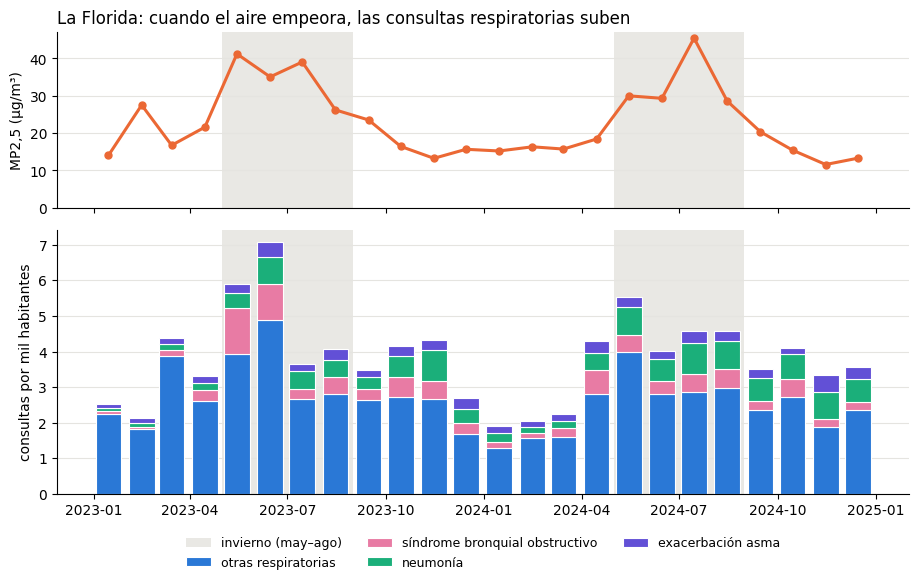

In [8]:
# @title Gráfico: aire y consultas, mes a mes
COLORES_CAUSA = {"otras respiratorias": "#2a78d6", "síndrome bronquial obstructivo": "#e87ba4", "neumonía": "#1baf7a", "exacerbación asma": "#6250d6"}
tabla = union.pivot_table(index="mes", columns="causa", values="consultas_por_mil", aggfunc="sum")
aire_mes = union.drop_duplicates("mes").set_index("mes").mp25
medio_mes = pd.to_timedelta(14, unit="D")          # puntos y barras en la mitad de cada mes

# Un panel por magnitud, con el mismo eje de tiempo (sin doble eje)
fig, (arriba, abajo) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [1, 1.5], "hspace": .1})
for panel in (arriba, abajo):
    for anio in range(VENTANA_INICIO, VENTANA_FIN + 1):
        panel.axvspan(pd.Timestamp(f"{anio}-05-01"), pd.Timestamp(f"{anio}-08-31"), color="#e9e8e4", lw=0, zorder=0,
                      label="invierno (may–ago)" if (panel is abajo and anio == VENTANA_INICIO) else None)
    panel.grid(axis="y", color="#e5e4e0"); panel.set_axisbelow(True)
    panel.spines[["top", "right"]].set_visible(False)

arriba.plot(pd.to_datetime(aire_mes.index) + medio_mes, aire_mes.values, color="#eb6834", lw=2.2, marker="o", ms=5)
arriba.set_ylabel("MP2,5 (µg/m³)"); arriba.set_ylim(bottom=0)
arriba.set_title(f"{NOMBRE_COMUNA}: cuando el aire empeora, las consultas respiratorias suben", loc="left")

base = pd.Series(0.0, index=tabla.index)
for causa in [c for c in COLORES_CAUSA if c in tabla.columns]:
    abajo.bar(pd.to_datetime(tabla.index) + medio_mes, tabla[causa], bottom=base, width=24, color=COLORES_CAUSA[causa], edgecolor="white", linewidth=.8, label=causa)
    base = base + tabla[causa]
abajo.set_ylabel("consultas por mil habitantes")
abajo.legend(loc="upper center", bbox_to_anchor=(.5, -.12), ncol=3, frameon=False, fontsize=9)
plt.show()

## Paso 3 · El mapa: dónde pesa más el invierno

Las mismas estaciones y los mismos polígonos oficiales (ya en memoria), ahora para toda la Región Metropolitana.

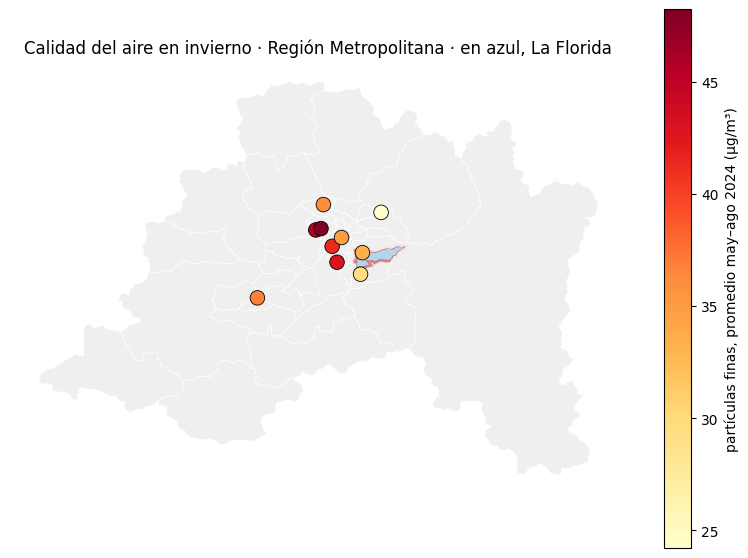

In [9]:
# @title El mapa: dónde pesa más el invierno (SUBDERE × SINCA)
from shapely import wkt as wkt_shapely

t0 = time.time()
puntos = con.execute(f"""
    SELECT e.estacion_id, e.nom_com, e.lon, e.lat, AVG(a.valor) AS mp25
    FROM aire_diario a JOIN estaciones e USING (estacion_fk)
    WHERE e.cut_reg = '13' AND year(a.fecha) = {VENTANA_FIN} AND month(a.fecha) BETWEEN 5 AND 8
    GROUP BY ALL""").df()
poligonos = con.execute("SELECT cut_com, ST_AsText(ST_Simplify(geometry, 0.003)) AS wkt FROM comunas WHERE cut_reg = '13'").df()
TIEMPOS["El mapa"] = time.time() - t0

fig, ax = plt.subplots(figsize=(8, 8))
for fila in poligonos.itertuples():
    g = wkt_shapely.loads(fila.wkt)
    es_tuya = fila.cut_com == CUT_COMUNA
    for parte in (list(g.geoms) if g.geom_type == "MultiPolygon" else [g]):
        x, y = parte.exterior.xy
        ax.fill(x, y, facecolor="#6BAED6" if es_tuya else "#EEEEEE", edgecolor="#D62728" if es_tuya else "white",
                lw=2 if es_tuya else .5, alpha=.5 if es_tuya else .9, zorder=1)
sc = ax.scatter(puntos.lon, puntos.lat, c=puntos.mp25, cmap="YlOrRd", s=110, edgecolors="black", linewidths=.6, zorder=3)
plt.colorbar(sc, ax=ax, shrink=.7, label=f"partículas finas, promedio may–ago {VENTANA_FIN} (µg/m³)")
ax.set_title(f"Calidad del aire en invierno · Región Metropolitana · en azul, {NOMBRE_COMUNA}")
ax.set_aspect("equal"); ax.set_axis_off()
plt.tight_layout(); plt.show()

In [10]:
# @title ⏱ Tiempo de ejecución
total = sum(TIEMPOS.values())
for etiqueta, segundos in TIEMPOS.items():
    print(f"{segundos:6.1f} s  {etiqueta}")
print(f"{'─' * 40}\n{total:6.1f} s  total de lecturas y consultas ({total / 60:.1f} min) · sin descargar un solo archivo")

  37.3 s  ¿Dónde? estaciones × comunas (SINCA × SUBDERE)
  13.1 s  Aire: mediciones diarias (SINCA)
  35.3 s  Salud: hechos REM + diccionario (DEIS)
   4.0 s  Población: Censo 2024 (INE)
   0.0 s  La unión (una consulta)
   0.0 s  El mapa
────────────────────────────────────────
  89.7 s  total de lecturas y consultas (1.5 min) · sin descargar un solo archivo


## Lo que acabas de ver

Cuatro instituciones, cuatro cosas que normalmente impiden juntar sus datos, y una sola consulta que las une:

* **¿Dónde?** Estación de aire ↔ comuna oficial *(MMA → SUBDERE)*.
* **¿De quién?** Código de comuna ↔ establecimientos de salud y población *(MINSAL ↔ INE)*.
* **¿Qué significa?** Código de prestación → nombre de la enfermedad *(REM → su diccionario)*.
* **¿Cuándo?** Mes a mes, de aire a salud.

Esto no es magia: es el dividendo de **estructurar bien los datos** (formato abierto, esquemas limpios, códigos oficiales, diccionarios). En el mundo de los silos esta pregunta es un proyecto, *cada vez que alguien la hace*.

**Lecturas honestas del resultado**
* Coinciden en el calendario, **no es causalidad**: el invierno trae también virus respiratorios.
* Las consultas se cuentan **donde está el establecimiento** (red pública que reporta al REM) y la población es **la que vive en la comuna**: es una tasa aproximada.
* El REM se publica con ~1 año de rezago.

**Con la misma base, preguntas que antes eran un proyecto pasan a ser una consulta:** comparar comunas con más y menos contaminación en el *mismo* invierno · separar por edad y sexo (el REM trae decenas de cortes) · ver olas de calor × urgencias · cruzar con transporte público.

**Referencias:** [Estonia: años de trabajo ahorrados con su capa de interoperabilidad (X-Road)](https://e-estonia.com/how-save-annually-820-years-of-work) · [Hospitalizaciones × MP2,5 en Santiago (Sci Rep 2024)](https://pmc.ncbi.nlm.nih.gov/articles/PMC11190141/) · [Submesa de Datos COVID, MinCiencia](https://www.minciencia.gob.cl/areas/minciencia-covid19/submesa-de-datos-covid19)

---

Datos servidos por el **Datopia Lakehouse** ([Data Observatory](https://dataobservatory.net)). Fuentes: SINCA (MMA), DEIS-REM (MINSAL), Censo 2024 (INE), División Político-Administrativa (SUBDERE). Notebook de demostración del concepto de interoperabilidad — bajo licencia MIT.